In [1]:
import pandas as pd
import numpy as np

In [ ]:
data = pd.read_csv(r'../data/lambda_1.2_mu_1.0.csv')
data

,start_time,total_time,machine_time,machine
0,0.115454,1.432914,1.427190,7dff33ebdcfa
1,2.506092,0.351456,0.348834,7dff33ebdcfa
2,3.089887,0.923626,0.920634,b5cf662e612e
3,3.887039,0.186045,0.183032,eac5ccafe3ab
4,5.385516,0.267959,0.265854,7dff33ebdcfa
...,...,...,...,...
593,498.598991,0.294081,0.291857,eac5ccafe3ab
594,499.053439,0.306581,0.304253,eac5ccafe3ab
595,499.325062,0.239419,0.204060,eac5ccafe3ab
596,498.403383,1.351929,1.350009,b5cf662e612e


In [4]:
duration = 500
initial_time = data['start_time'].min()
final_time = initial_time + duration
data['final_time'] = data['start_time'] + data['total_time']

In [5]:
# utilization X = jobs done / observed time
# basically ammount of rows / duration of experiment
X = (data['final_time'] <= data['start_time'].min() + duration).sum() / duration
X

np.float64(1.194)

In [6]:
# E[R] average time of response
# Only when the simulation was running
t0 = data['start_time'].min()
completed = data['final_time'] <= t0 + duration
er = data.loc[completed, 'total_time'].mean()
er


np.float64(1.5522339909011724)

In [7]:
# E[N] average amount of requests in the system
# Computed by using the start_time and total_time
# using this one can know the amount of requests in the system at any given time
t0 = data['start_time'].min()
t1 = t0 + duration
arrive = data['start_time'].to_numpy()
depart = data['final_time'].to_numpy()
overlap = np.maximum(0.0, np.minimum(depart, t1) - np.maximum(arrive, t0))
en = overlap.sum() / duration
en

np.float64(1.853367385135999)

In [10]:
# Utilization Ui = machine i used time / total time
machine_ids = {
    name: i
    for i, name in enumerate(sorted(data['machine'].unique()), start=1)
}
data['machine_id'] = data['machine'].map(machine_ids)

t0 = data['start_time'].min()
t1 = t0 + duration
busy_end = data['final_time'].to_numpy()
busy_start = busy_end - data['machine_time'].to_numpy()
data['busy_time'] = np.maximum(
    0.0, np.minimum(busy_end, t1) - np.maximum(busy_start, t0)
)

ui = data.groupby('machine_id')['busy_time'].sum() / duration
print(machine_ids)
ui

{'7dff33ebdcfa': 1, 'b5cf662e612e': 2, 'eac5ccafe3ab': 3}


machine_id
1    0.389325
2    0.380243
3    0.369270
Name: busy_time, dtype: float64

np.float64(0.3893254180000006)

In [9]:
# Little's law verification
# X * E[R] approx E[N]
print(X * er)
print(en)

1.8533673851359997
1.853367385135999


In [10]:
def func(data):
    points = []
    for i in range(1, 500):
        duration = i
        initial_time = data['start_time'].min()
        final_time = initial_time + duration
        X = (data['final_time'] <= data['start_time'].min() + duration).sum() / duration
        t0 = data['start_time'].min()
        completed = data['final_time'] <= t0 + duration
        er = data.loc[completed, 'total_time'].mean()

        t0 = data['start_time'].min()
        t1 = t0 + duration
        arrive = data['start_time'].to_numpy()
        depart = data['final_time'].to_numpy()
        overlap = np.maximum(0.0, np.minimum(depart, t1) - np.maximum(arrive, t0))
        en = overlap.sum() / duration
        points.append([X, en, er])
    return points

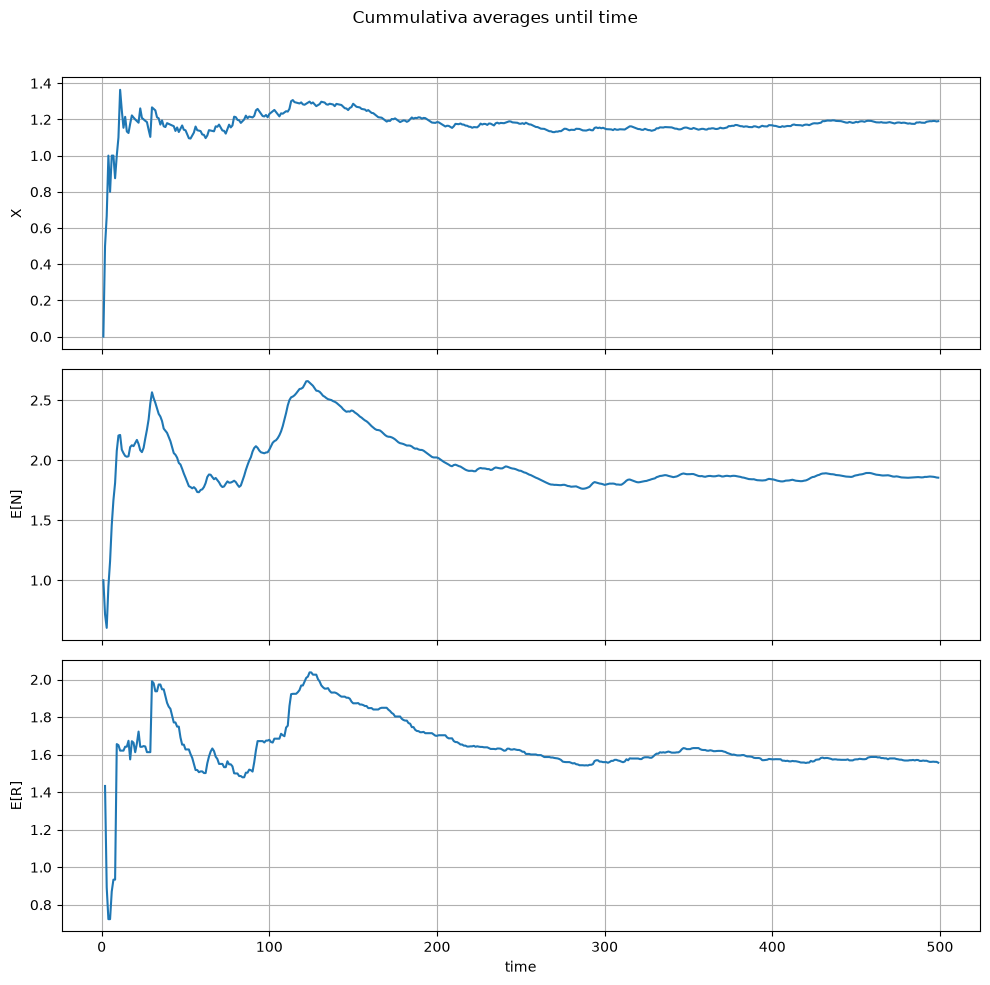

In [15]:
import matplotlib.pyplot as plt

points = np.array(func(data))
i = np.arange(1, len(points) + 1)

fig, axes = plt.subplots(3, 1, figsize=(10, 10), sharex=True)
for ax, col, label in zip(axes, range(3), ["X", "E[N]", "E[R]"]):
    ax.plot(i, points[:, col])
    ax.set_ylabel(label)
    ax.grid(True)

axes[-1].set_xlabel("time")
fig.suptitle("Cummulativa averages until time", fontsize=12)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

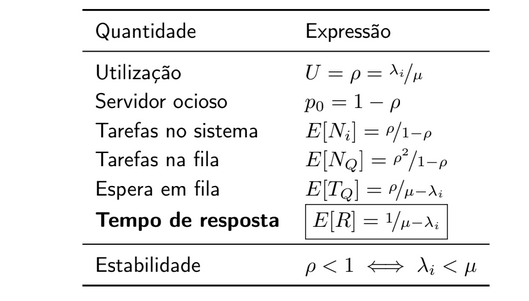

In [25]:
lambdai = 1.2 / 3
mu = 1
rho = lambdai / mu

Eni = rho / (1-rho)
Er = 1/(mu - lambdai)

print(rho, ui)
print(3 * Eni, en)
print(Er, er)

0.39999999999999997 machine_id
1    0.389325
2    0.380243
3    0.369270
Name: busy_time, dtype: float64
1.9999999999999996 1.853367385135999
1.6666666666666665 1.5522339909011724
